In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load data
df = pd.read_csv('/content/Salary Data.csv')

# Check first 5 rows
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [ ]:
df.describe()

,Age,Years of Experience,Salary,Cluster
count,373.000000,373.000000,373.000000,373.000000
mean,37.431635,10.030831,100577.345845,1.040214
std,7.069073,6.557007,48240.013482,0.826960
min,23.000000,0.000000,350.000000,0.000000
25%,31.000000,4.000000,55000.000000,0.000000
50%,36.000000,9.000000,95000.000000,1.000000
75%,44.000000,15.000000,140000.000000,2.000000
max,53.000000,25.000000,250000.000000,2.000000


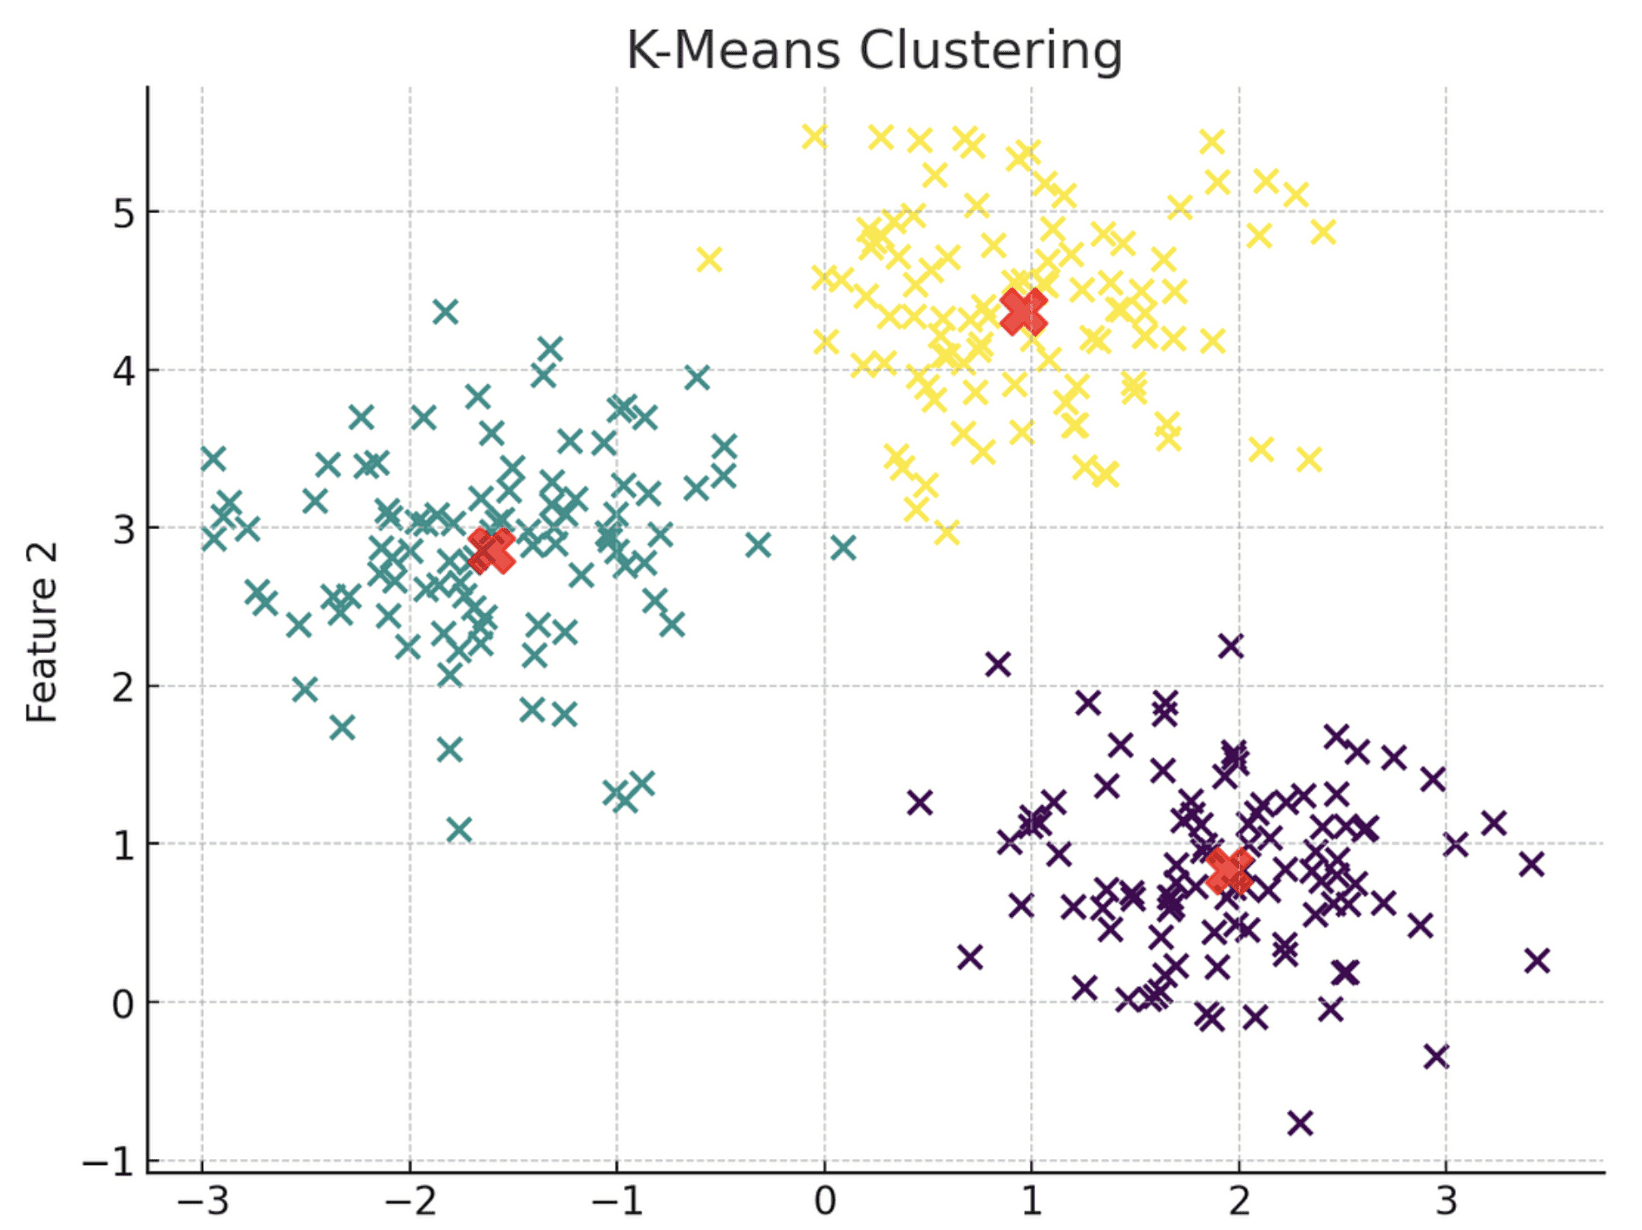

In [ ]:
X = df[['Age', 'Years of Experience', 'Salary']].copy()

# Drop missing values if any
X = X.dropna()

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

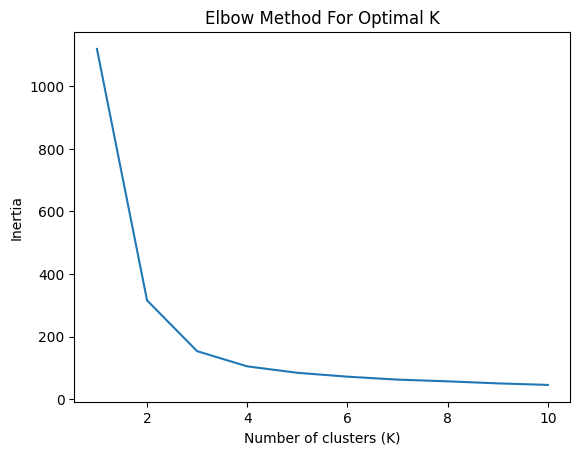

In [ ]:
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot elbow curve
plt.plot(K_range, inertia)
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal K')
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df.loc[X.index, 'Cluster'] = kmeans.fit_predict(X_scaled)

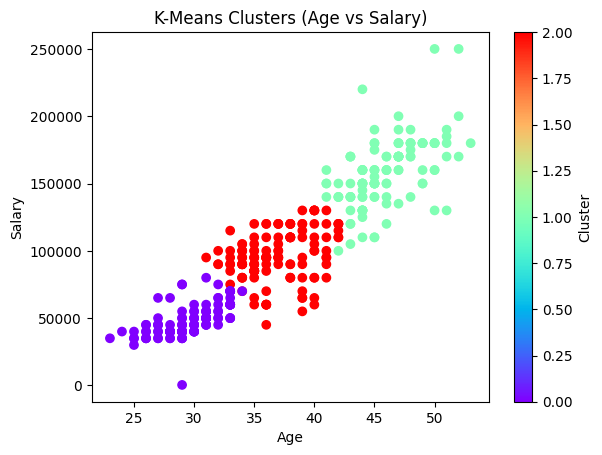

In [ ]:
plt.scatter(df['Age'], df['Salary'], c=df['Cluster'], cmap='rainbow')
plt.xlabel('Age')
plt.ylabel('Salary')
plt.title('K-Means Clusters (Age vs Salary)')
plt.colorbar(label='Cluster')
plt.show()

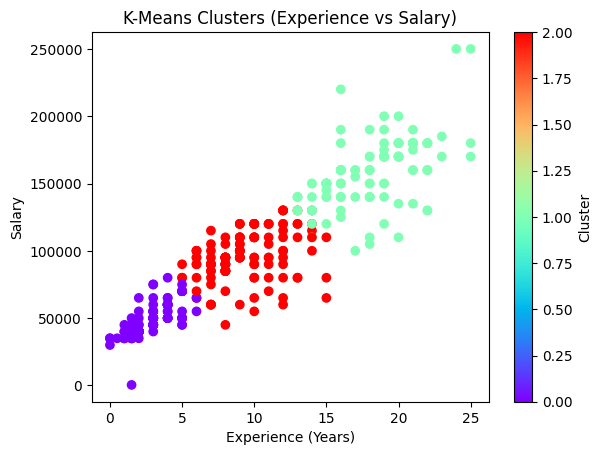

In [ ]:
plt.scatter(df['Years of Experience'], df['Salary'], c=df['Cluster'], cmap='rainbow')
plt.xlabel('Experience (Years)')
plt.ylabel('Salary')
plt.title('K-Means Clusters (Experience vs Salary)')
plt.colorbar(label='Cluster')
plt.show()

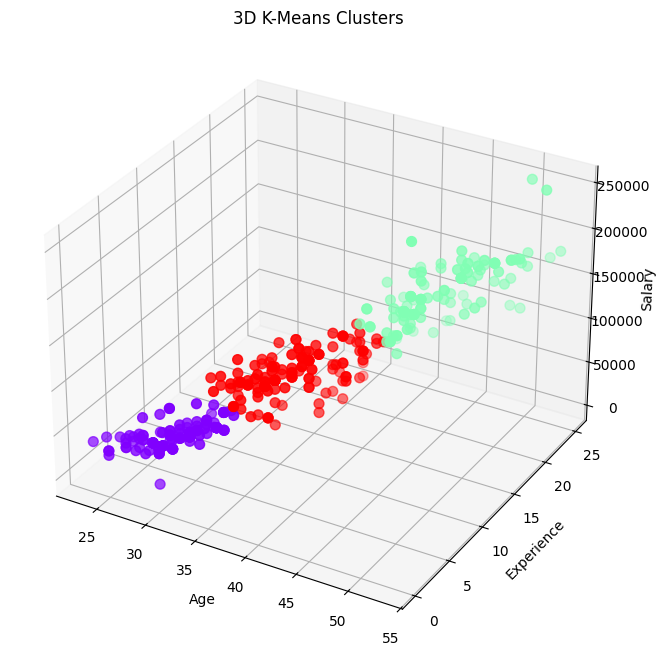

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(df['Age'], df['Years of Experience'], df['Salary'], c=df['Cluster'], cmap='rainbow', s=50)
ax.set_xlabel('Age')
ax.set_ylabel('Experience')
ax.set_zlabel('Salary')
plt.title('3D K-Means Clusters')
plt.show()

In [ ]:
cluster_summary = df.groupby('Cluster')[['Age', 'Years of Experience', 'Salary']].mean()
print(cluster_summary)

               Age  Years of Experience         Salary
Cluster                                               
0.0      29.633333             2.829167   48294.583333
1.0      46.033898            18.135593  158855.932203
2.0      36.844444             9.348148   96111.111111


## 8. Evaluate Clusters (Check quality)

In [ ]:
from sklearn.metrics import silhouette_score

# Calculate Silhouette Score
silhouette_avg = silhouette_score(X_scaled, df.loc[X.index, 'Cluster'])
print(f"Silhouette Score: {silhouette_avg:.2f}")

# A higher silhouette score indicates better-defined clusters.

Silhouette Score: 0.56


## 9. Interpret Results (Business insights)

In [ ]:
print("Cluster Summary (Mean values for Age, Years of Experience, and Salary):")
print(cluster_summary)

Cluster Summary (Mean values for Age, Years of Experience, and Salary):
               Age  Years of Experience         Salary
Cluster                                               
0.0      29.633333             2.829167   48294.583333
1.0      46.033898            18.135593  158855.932203
2.0      36.844444             9.348148   96111.111111


Based on the cluster summary:

*   **Cluster 0 (Entry-Level/Junior Professionals):** This cluster represents younger individuals (average age ~29) with fewer years of experience (average ~2.8 years) and the lowest average salary (~$48,294). This group likely consists of employees early in their careers.
*   **Cluster 1 (Senior/Experienced Professionals):** This cluster includes older individuals (average age ~46) with significant experience (average ~18.1 years) and the highest average salary (~$158,855). This group likely represents senior-level employees or executives.
*   **Cluster 2 (Mid-Career Professionals):** This cluster falls in between the other two, with an average age of ~36, moderate experience (average ~9.3 years), and a mid-range average salary (~$96,111). This group could be mid-level managers or experienced individual contributors.

These insights can be valuable for targeted HR strategies, compensation planning, and talent management.

## 10. Deploy & Monitor (Save model, predict new)

In [ ]:
import joblib

# Save the KMeans model and the StandardScaler
joblib.dump(kmeans, 'kmeans_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("KMeans model and StandardScaler saved.")


KMeans model and StandardScaler saved.


In [ ]:
# Load the saved model and scaler
loaded_kmeans = joblib.load('kmeans_model.pkl')
loaded_scaler = joblib.load('scaler.pkl')

# Example of predicting for a new data point
# Let's say a new employee is 30 years old, has 4 years of experience, and a salary of 70000
new_data = pd.DataFrame([{'Age': 37, 'Years of Experience': 7, 'Salary': 97000}])

# Scale the new data using the loaded scaler
new_data_scaled = loaded_scaler.transform(new_data)

# Predict the cluster for the new data
new_cluster = loaded_kmeans.predict(new_data_scaled)
print(f"The new data point belongs to Cluster: {new_cluster[0]}")

The new data point belongs to Cluster: 2
